# Load data

In [4]:
import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset
from sklearn.model_selection import train_test_split

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.0
Torchvision: 0.28.0
Device: mps


In [5]:
pacs = load_dataset("flwrlabs/pacs", split="train")

print("Total images:", len(pacs))
print("Domains:", Counter(pacs["domain"]))
print("Classes:", pacs.features["label"].names)

Generating train split: 100%|██████████| 9991/9991 [00:01<00:00, 8923.32 examples/s] 


Total images: 9991
Domains: Counter({'sketch': 3929, 'cartoon': 2344, 'art_painting': 2048, 'photo': 1670})
Classes: ['dog', 'elephant', 'giraffe', 'guitar', 'horse', 'house', 'person']


In [6]:
TARGET_DOMAIN = "sketch"

domains = np.asarray(pacs["domain"])
labels = np.asarray(pacs["label"])

source_idx = np.where(domains != TARGET_DOMAIN)[0]
target_idx = np.where(domains == TARGET_DOMAIN)[0]

strata = [f"{domains[i]}_{labels[i]}" for i in source_idx]

train_idx, val_idx = train_test_split(
    source_idx,
    test_size=0.1,
    random_state=SEED,
    stratify=strata,
)

train_ds = pacs.select(train_idx.tolist())
val_ds = pacs.select(val_idx.tolist())
test_ds = pacs.select(target_idx.tolist())

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("Target domain:", TARGET_DOMAIN)

Train: 5455
Validation: 607
Test: 3929
Target domain: sketch


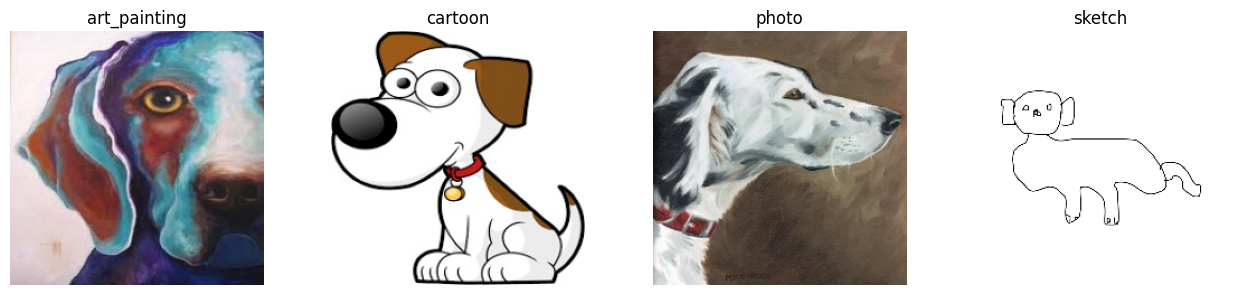

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

for ax, domain in zip(axes, sorted(set(domains))):
    idx = np.where(domains == domain)[0][0]
    sample = pacs[int(idx)]

    ax.imshow(sample["image"].convert("RGB"))
    ax.set_title(domain)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Load Model

In [8]:
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torch.utils.data import Dataset, DataLoader

weights = MobileNet_V3_Small_Weights.DEFAULT

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = weights.transforms()

In [9]:
class PACSDataset(Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]
        image = self.transform(sample["image"].convert("RGB"))
        return image, int(sample["label"])

In [10]:
BATCH_SIZE = 32

train_loader = DataLoader(
    PACSDataset(train_ds, train_transform),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
)

val_loader = DataLoader(
    PACSDataset(val_ds, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

test_loader = DataLoader(
    PACSDataset(test_ds, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 171
Validation batches: 19
Test batches: 123


In [11]:
import torch.nn as nn

NUM_CLASSES = len(pacs.features["label"].names)

model = mobilenet_v3_small(weights=weights)
model.classifier[-1] = nn.Linear(
    model.classifier[-1].in_features, NUM_CLASSES
)
model = model.to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /Users/edsonodake/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 20.2MB/s]


Parameters: 1525031
Trainable: 1525031


In [12]:
import time
from tqdm.auto import tqdm

def train_epoch(model, loader):
    model.train()
    total_loss = 0.0

    for xb, yb in tqdm(loader, desc="Training", leave=False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(yb)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        predictions = model(xb).argmax(dim=1)
        correct += (predictions == yb).sum().item()
        total += len(yb)

    return correct / total


start = time.perf_counter()
train_loss = train_epoch(model, train_loader)

if DEVICE.type == "mps":
    torch.mps.synchronize()

elapsed = time.perf_counter() - start
val_acc = evaluate(model, val_loader)

print(f"Training time: {elapsed:.1f} seconds")
print(f"Training loss: {train_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

if DEVICE.type == "mps":
    print(f"MPS allocated: {torch.mps.current_allocated_memory() / 1024**3:.2f} GB")

Training time: 186.1 seconds
Training loss: 1.0197
Validation accuracy: 0.8880
MPS allocated: 0.02 GB
